In [2]:
%pip install tensorflow tensorflow-datasets scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Chit 27: Caltech-101 VGG16 fine-tuning
# Step 1: Import libraries
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.model_selection import train_test_split

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

In [4]:
# Load Caltech-101
(ds,), info = tfds.load(
    "caltech101",
    split=["train"],
    as_supervised=True,
    with_info=True
)
all_names = info.features["label"].names

In [5]:
# Select five categories
selected_names = ["airplanes", "ant", "camera", "cannon", "chair"]
missing = [name for name in selected_names if name not in all_names]
if missing:
    raise ValueError(f"Categories not found: {missing}")

selected_ids = [all_names.index(name) for name in selected_names]

# Select images, resize, and encode labels as 0–4
images, labels = [], []
for image, label in tfds.as_numpy(ds):
    label = int(label)
    if label in selected_ids:
        images.append(tf.image.resize(image, (224, 224)).numpy())
        labels.append(selected_ids.index(label))

X = np.asarray(images, dtype=np.float32)
y = np.asarray(labels, dtype=np.int32)

# Split into train, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

In [6]:
# Prepare datasets: VGG16 preprocessing and one-hot labels
def make_dataset(images, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if shuffle:
        ds = ds.shuffle(len(images), seed=SEED)

    def prepare(image, label):
        image = preprocess_input(image)
        label = tf.one_hot(label, depth=len(selected_names))
        return image, label

    return ds.map(prepare).batch(16).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, shuffle=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

# Load VGG16 and freeze lower convolutional layers
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5")

In [7]:
# Add the custom classification head
inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(len(selected_names), activation="softmax")(x)
model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

Epoch 1/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 48s 7s/step - accuracy: 0.3048 - loss: 3.8992 - val_accuracy: 0.7273 - val_loss: 1.0403
Epoch 2/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 40s 6s/step - accuracy: 0.6286 - loss: 1.1117 - val_accuracy: 0.7273 - val_loss: 0.9311
Epoch 3/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 38s 6s/step - accuracy: 0.7524 - loss: 0.6980 - val_accuracy: 0.8636 - val_loss: 0.6066
Epoch 4/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 31s 4s/step - accuracy: 0.8857 - loss: 0.3916 - val_accuracy: 0.9091 - val_loss: 0.3867
Epoch 5/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 27s 4s/step - accuracy: 0.8857 - loss: 0.3286 - val_accuracy: 0.9091 - val_loss: 0.2652


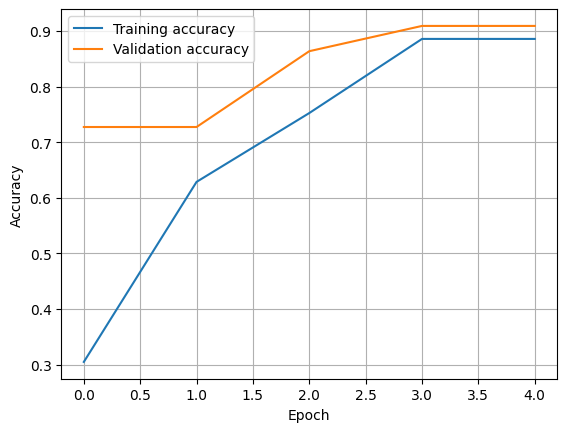

In [8]:
# Train and plot training/validation accuracy
history = model.fit(train_ds, validation_data=val_ds, epochs=5)

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

In [9]:
# Evaluate on the held-out test set
_, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

# Predict five test images
for i in range(min(5, len(X_test))):
    image = preprocess_input(X_test[i].copy())[None, ...]
    probabilities = model.predict(image, verbose=0)[0]
    predicted = np.argmax(probabilities)
    print(
        f"Sample {i + 1}: predicted={selected_names[predicted]} | "
        f"actual={selected_names[y_test[i]]}"
    )

Test accuracy: 91.30%
Sample 1: predicted=airplanes | actual=airplanes
Sample 2: predicted=ant | actual=chair
Sample 3: predicted=chair | actual=chair
Sample 4: predicted=camera | actual=camera
Sample 5: predicted=chair | actual=ant
